<a href="https://colab.research.google.com/github/Ahmettufan3310/74-musteri-segmentasyonu-rfm/blob/main/notebooks/06_segment_profilleme.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

url = "https://raw.githubusercontent.com/Ahmettufan3310/74-musteri-segmentasyonu-rfm/main/data/kume_sonuclari.csv"
df = pd.read_csv(url)
print(df.shape)
print(df.head())

(4333, 6)
   CustomerID  Recency  Frequency  Monetary  IlkAlisveris  Kume
0     12347.0        2          7   4310.00           367     1
1     12348.0       75          4   1437.24           358     2
2     12349.0       19          1   1457.55            19     0
3     12350.0      310          1    294.40           310     3
4     12352.0       36          7   1385.74           297     2


In [2]:
# kümelerin RFM profiline göre isimler
isim = {0: 'Yeni/Potansiyel', 1: 'VIP', 2: 'Sadık', 3: 'Uykuda'}
df['Segment'] = df['Kume'].map(isim)
print(df['Segment'].value_counts())

Segment
Uykuda             1595
Sadık              1187
Yeni/Potansiyel     837
VIP                 714
Name: count, dtype: int64


In [3]:
profil = df.groupby('Segment').agg(
    Musteri_Sayisi=('CustomerID', 'count'),
    Recency=('Recency', 'median'),
    Frequency=('Frequency', 'median'),
    Monetary=('Monetary', 'median'),
    Toplam_Ciro=('Monetary', 'sum'),
)
profil['Musteri_Orani_%'] = (profil['Musteri_Sayisi'] / profil['Musteri_Sayisi'].sum() * 100).round(1)
profil['Ciro_Payi_%'] = (profil['Toplam_Ciro'] / profil['Toplam_Ciro'].sum() * 100).round(1)
profil = profil.round(1).sort_values('Monetary', ascending=False)
print(profil)

                 Musteri_Sayisi  Recency  Frequency  Monetary  Toplam_Ciro  \
Segment                                                                      
VIP                         714      8.0       10.0    3623.5    5497842.8   
Sadık                      1187     54.0        4.0    1320.2    1965954.1   
Yeni/Potansiyel             837     18.0        2.0     450.3     439219.8   
Uykuda                     1595    179.0        1.0     292.5     543048.3   

                 Musteri_Orani_%  Ciro_Payi_%  
Segment                                        
VIP                         16.5         65.1  
Sadık                       27.4         23.3  
Yeni/Potansiyel             19.3          5.2  
Uykuda                      36.8          6.4  


In [4]:
oneri = {
    'VIP': 'Sadakat programı, özel indirimler, yeni ürünlere erken erişim; kaybetmemek öncelik.',
    'Sadık': 'Çapraz satış ve üst segment ürün önerileri; düzenli kampanyalarla VIP seviyesine taşıma.',
    'Yeni/Potansiyel': 'Hoş geldin kampanyası, ikinci alışverişe özel indirim; tekrar alım alışkanlığı kazandırma.',
    'Uykuda': 'Geri kazanım e-postası ve kişisel indirim kuponu; tepki vermeyenler için düşük maliyetli iletişim.',
}
for seg in profil.index:
    print(f"{seg}: {oneri[seg]}")

VIP: Sadakat programı, özel indirimler, yeni ürünlere erken erişim; kaybetmemek öncelik.
Sadık: Çapraz satış ve üst segment ürün önerileri; düzenli kampanyalarla VIP seviyesine taşıma.
Yeni/Potansiyel: Hoş geldin kampanyası, ikinci alışverişe özel indirim; tekrar alım alışkanlığı kazandırma.
Uykuda: Geri kazanım e-postası ve kişisel indirim kuponu; tepki vermeyenler için düşük maliyetli iletişim.


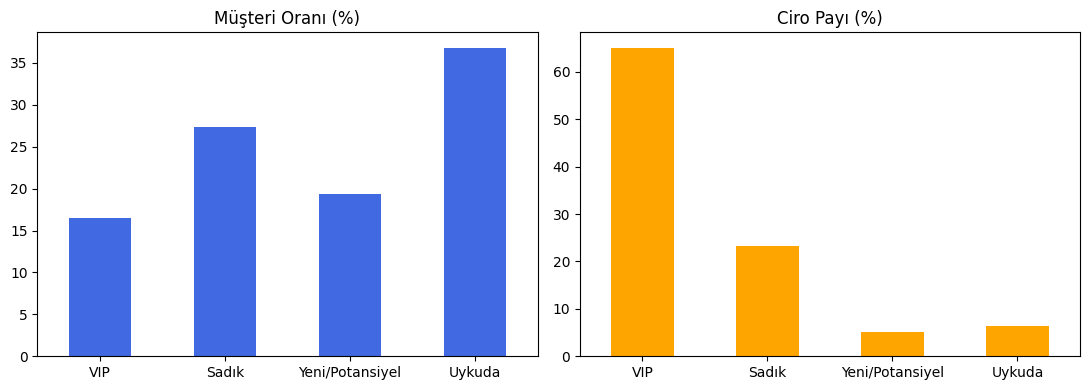

In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
profil['Musteri_Orani_%'].plot(kind='bar', ax=ax[0], color='royalblue')
ax[0].set_title('Müşteri Oranı (%)'); ax[0].set_xlabel('')
profil['Ciro_Payi_%'].plot(kind='bar', ax=ax[1], color='orange')
ax[1].set_title('Ciro Payı (%)'); ax[1].set_xlabel('')
for a in ax: a.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

In [6]:
df.to_csv('segment_sonuclari.csv', index=False)
print("Kaydedildi")

Kaydedildi
